# Finding asteroids in Hubble exposures with ROSALIA

***

## What is this? 

`ROSALIA` allows the user to estimate much more than stray-light on Roman WFI exposures. In this notebook, we will demonstrate how to use of ROSALIA to find out which Solar System Objects are in your Hubble datasets. Following the previous tutorial, we will use datasets stored in the Roman Nexus cloud. We will access a pre-generated Roman mock observation, generate a ROSALIA exposure object, and then use the `rosalia.core.exposure.get_nearby_ssos()` method to automatically query and propagate the orbits of known Solar System Objects stored in the Minor Planet Center database. 


Additional information about ROSALIA can be found in the [ROSALIA for Roman documentation](https://rosalia.readthedocs.io/en/latest/) article on ReadTheDocs.

## How to start

To run this notebook, please activate the "rosalia" kernel at the top right of your window.

## Imports

- *rosalia* for Roman/WFI stray-light analysis
- *matplotlib* for plotting the resulting asteroids tracks

In [1]:
%matplotlib inline
import rosalia as rs
import matplotlib.pyplot as plt 

In [2]:
input_name = "/Users/aborlaff/NASA/ROSALIA_DEPOT/MAST_2026-10-19T1427/MAST_2026-10-19T1427/HST/jfk406olq_flc.fits"

In [3]:
import numpy as np
SCIEXTS = rs.utils.detect_sci_extensions(input_name)
np.linspace(1, len(SCIEXTS), len(SCIEXTS), dtype="int32").tolist()

[1, 2]

## Quick start

First we select a Roman mock image stored at the S3 bucket in Nexus. We generate a ROSALIA exposure object by using rosalia.core.exposure. ROSALIA will automatically detect that the path is a Nexus S3 file, but it also works with local fits or asdf files. 

In [4]:
# With this line we generate the exposure object. This is the first step in any ROSALIA analysis. 
rosalia_exposure = rs.core.exposure(filename=input_name)

DATA / WCS mode
Query failed without known error message; received the following response:
API VERSION: 1.2
API SOURCE: NASA/JPL Horizons API

Body #-48 does not have an IAU-defined cartographic rotation model

Using Lagrange point L2 as a fallback for the observer position.


To estimate the locations of the SSOs, ROSALIA uses another package built by our team named `EPHESSOS` (https://pypi.org/project/ephessos/). `EPHESSOS` automatically queries orbital parameters from the Minor Planet Center database (https://www.minorplanetcenter.net/iau/mpc.html), and propagates the orbits through JPL/Horizons, returning the expected trajectory along the duration of the Roman / WFI exposure. All this happens in the background after using the `rosalia_exposure.get_nearby_ssos()` method. 

In [5]:
# Here we execute the Solar System Object query method to estimate the trajectories of known SSOs. 
cone_search, ssos_db = rosalia_exposure.get_nearby_ssos(time_step="1m", verbose=False)

100%|██████████| 3/3 [00:01<00:00,  2.72it/s]


The ssos_db is a pandas.DataFrame table that contains the predicted location of all known Solar System Objects in the Minor Planet Center database nearby the focal plane array of the designated Roman WFI exposure.

### Now let's plot the results! 

Getting detector corners
Plotting...


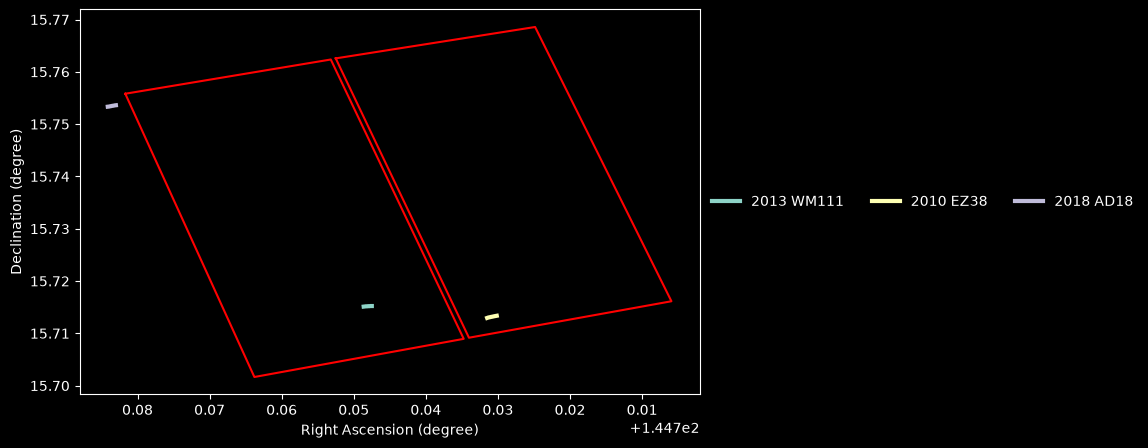

In [6]:
plt.style.use('dark_background')

ax = rosalia_exposure.plot_footprint(figsize=(8,5))

for i in range(len(ssos_db)):
    ax.plot(ssos_db[i]["RA_deg_ICRF"], 
            ssos_db[i]["DEC_deg_ICRF"], 
            label=ssos_db[i]["Designation"].iloc[0], 
            linewidth=3)
    ax.legend(frameon=False, loc='center left', bbox_to_anchor=(1, 0.5), ncol=3)
ax.xaxis.set_inverted(True) 
plt.savefig("jfk406olq_flc_ssos.png", dpi=300)
plt.show()

## About this Notebook

**Author:** Alejandro S. Borlaff - NASA Ames Research Center (Code S) - a.s.borlaff@nasa.gov 

**Updated on** October 20, 2026. 

<table width="100%" style="border:none; border-collapse:collapse;">

  <tr style="border:none;">
    <td style="border:none; width:180px; white-space:nowrap;">
       <a href="#top" style="text-decoration:none; color:#0066cc;"> Top of page</a>
    </td>
    <td style="border:none; text-align:center;">
        <img src="https://raw.githubusercontent.com/spacetelescope/roman_notebooks/refs/heads/main/roman_logo.png" alt="roman_logo" width="50px">
    </td>
    <td style="border:none; text-align:right;">
       <img src="https://raw.githubusercontent.com/spacetelescope/roman_notebooks/refs/heads/main/stsci_logo2.png" width="90">
    </td>
  </tr>
</table>